<a href="https://colab.research.google.com/github/Mariano-ds/tpRL_2026/blob/main/mariano_tp1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Guía del TP — Decision Transformer e IQL para recomendaciones

Esta guía acompaña a la [consigna](CONSIGNA.md) y sigue el orden en que se presenta el TP en clase. Para cada parte explica la idea, la ilustra con ejemplos chicos resueltos a mano, muestra cómo usar el [protocolo común](protocolo/PROTOCOLO.md) y da esqueletos de código para completar. Las partes marcadas con `TODO` son las que implementa cada grupo.

Los esqueletos son una forma posible de organizar el código, no la única. Cualquier diseño es válido si respeta el protocolo y está documentado.

## Contenido

0. [Preparación](#0-preparación)
1. [Los datos](#1-los-datos)
2. [El problema como MDP](#2-el-problema-como-mdp)
3. [El protocolo de evaluación](#3-el-protocolo-de-evaluación)
4. [Decision Transformer](#4-decision-transformer)
5. [IQL](#5-iql)
6. [Calidad de los logs](#6-calidad-de-los-logs)
7. [Semillas y reporte](#7-semillas-y-reporte)
8. [Errores frecuentes](#8-errores-frecuentes)
9. [Preguntas para discutir](#9-preguntas-para-discutir)
10. [Referencias](#10-referencias)

## 0. Preparación


In [1]:
# Clonar el repositorio en el disco local rápido de Colab (/content)
!git clone https://github.com/DiploDatos/AprendizajePorRefuerzos.git

# Moverse a la raíz del proyecto (usar %cd)
%cd /content/AprendizajePorRefuerzos/2026/tp

# Registrar la raíz en el path de Python para evitar ModuleNotFoundError
import sys
tp_path = "/content/AprendizajePorRefuerzos/2026/tp"
if tp_path not in sys.path:
    sys.path.insert(0, tp_path)

# Instalar dependencias del proyecto
%pip install -q -r requirements.txt

Cloning into 'AprendizajePorRefuerzos'...
remote: Enumerating objects: 1397, done.
remote: Counting objects: 100% (276/276), done.
remote: Compressing objects: 100% (114/114), done.
remote: Total 1397 (delta 195), reused 164 (delta 162), pack-reused 1121 (from 2)
Receiving objects: 100% (1397/1397), 84.05 MiB | 10.41 MiB/s, done.
Resolving deltas: 100% (704/704), done.
Updating files: 100% (90/90), done.
/content/AprendizajePorRefuerzos/2026/tp


Todo el código del TP se ejecuta desde `2026/tp`. Antes de escribir nada, verificar que el protocolo funciona:

In [2]:
%cd /content/AprendizajePorRefuerzos/2026/tp
!python -m pytest protocolo/tests
!python -m protocolo.evaluar --dataset netflix --output outputs/baselines_netflix

/content/AprendizajePorRefuerzos/2026/tp
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/AprendizajePorRefuerzos/2026/tp
plugins: platformdirs-4.14.3, anyio-4.16.0, typeguard-4.6.0, langsmith-0.14.17
collected 19 items                                                             

protocolo/tests/test_logs.py ....                                        [ 21%]
protocolo/tests/test_protocolo.py ...............                        [100%]

============================== 19 passed in 1.31s ==============================
                                      return  normalized  hit_rate  ndcg@10
policy          warmup group_visible                                       
group_mean      0      False          88.421       0.689     0.894    0.924
                       True           90.066       0.742     0.918    0.936
                5      False          66.735       0.705     

El primer comando corre los tests del protocolo. El segundo evalúa las líneas base, imprime un resumen y escribe `sesiones.csv`, `resumen.csv` y `resumen_por_grupo.csv` en `outputs/baselines_netflix/`. Sus números deben coincidir con la tabla del protocolo. Si no coinciden, hay un problema de instalación o de datos que conviene resolver antes de seguir.

Elegir el dataset en `config_dataset.py` o pasarlo como argumento. Netflix tiene 752 ítems (películas) y Goodreads 472 (libros). Los dos tienen 8 grupos de usuarios.

## 1. Los datos

### 1.1 Un primer vistazo

Cada usuario es un grupo y una lista de ítems con su rating, de 1 a 5. Los ítems son IDs, de 0 a 751 en Netflix, sin título ni otros atributos. Así se ven tres usuarios de train de Netflix, mostrando sus primeros 6 ítems:

| user_id | grupo | ítems valorados | primeros ítems | sus ratings | rating medio |
|---:|---:|---:|---|---|---:|
| 0 | 0 | 77 | 472, 97, 122, 654, 709, 467 | 4, 3, 4, 3, 5, 4 | 3,84 |
| 6000 | 3 | 178 | 632, 358, 42, 76, 193, 691 | 5, 2, 3, 1, 3, 2 | 2,75 |
| 12000 | 6 | 167 | 650, 95, 493, 250, 442, 247 | 5, 2, 4, 3, 2, 1 | 3,37 |

Cada usuario valoró una cantidad distinta de ítems, y cada uno vio ítems distintos. El usuario del grupo 3 pone notas más bajas en promedio.

La misma información, en formato largo (una fila por interacción), es la tabla que se arma en la [exploración](#14-exploración). La última columna no está en los datos de train: es la media μ del grupo 0 para ese ítem, tomada de `groups/mu_netflix8.csv`. Se agrega acá sólo para mostrar que cada rating es esa media más ruido:

| user_id | grupo | posición | ítem | rating | μ[0, ítem] |
|---:|---:|---:|---:|---:|---:|
| 0 | 0 | 0 | 472 | 4 | 4,6 |
| 0 | 0 | 1 | 97 | 3 | 4,3 |
| 0 | 0 | 2 | 122 | 4 | 4,0 |
| 0 | 0 | 3 | 654 | 3 | 2,5 |
| 0 | 0 | 4 | 709 | 5 | 4,0 |
| 0 | 0 | 5 | 467 | 4 | 4,1 |

Los usuarios de test tienen un rating para **cada** ítem del catálogo, guardados en el orden de los IDs. Su `user_id` es la posición en el archivo de test: no tienen relación con los usuarios de train de igual número.

| user_id (test) | grupo | ítem 0 | ítem 1 | ítem 2 | ítem 3 | ítem 4 | ítem 5 | … | ítem 751 |
|---:|---:|---:|---:|---:|---:|---:|---:|---|---:|
| 0 | 0 | 4 | 1 | 3 | 5 | 5 | 4 | … | 5 |
| 600 | 3 | 2 | 5 | 1 | 1 | 1 | 1 | … | 3 |

El grupo importa porque los grupos tienen gustos distintos. Estas son las medias μ de tres ítems en cada grupo, del mismo archivo. La sección 1.2 explica qué son y por qué no se pueden usar en las políticas:

| ítem | g0 | g1 | g2 | g3 | g4 | g5 | g6 | g7 |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 144 | 4,9 | 4,7 | 4,5 | 4,4 | 4,9 | 4,7 | 4,8 | 4,4 |
| 3 | 4,7 | 3,5 | 3,4 | 1,8 | 4,5 | 3,5 | 3,8 | 2,5 |
| 573 | 1,7 | 1,9 | 2,0 | 1,0 | 5,0 | 1,4 | 2,4 | 1,4 |

- El ítem 144 le gusta a todos: recomendarlo es buena idea sin saber nada del usuario.
- El ítem 573 sólo le gusta al grupo 4. Para el resto es de lo peor del catálogo. Recomendarlo sin conocer el grupo es una mala apuesta, aunque para un grupo sea perfecto.
- El ítem 3 está en el medio: a los grupos 0 y 4 les gusta mucho y al grupo 3 muy poco.

Gran parte del TP gira alrededor de esta tabla: qué hacer cuando se conoce el grupo, qué hacer cuando no, y cómo averiguarlo durante la sesión.

### 1.2 De dónde salen

Los datos son **sintéticos**, construidos a partir de Netflix y Goodreads:

1. Los usuarios reales se agruparon por preferencias en 8 grupos (clusters).
2. Para cada grupo g e ítem i hay una media μ[g, i] y un desvío σ[g, i] de los ratings.
3. Cada usuario sintético pertenece a un grupo. Sus ratings se comportan como sorteados alrededor de μ[g, i] con desvío σ[g, i], dentro del rango 1–5. Los promedios por grupo e ítem de train coinciden con μ con una correlación de 0,997. En train son enteros. En el test de Goodreads son continuos.

Esto tiene dos consecuencias importantes para todo el TP:

- **Dos usuarios del mismo grupo tienen los mismos gustos esperados.** Lo que los distingue es ruido. Saber el grupo de un usuario es saber casi todo lo que se puede saber de él.
- **El rating de un ítem no depende de qué otros ítems vio antes el usuario.** No hay cansancio, ni novedad, ni efectos de orden.

Los archivos `groups/*.csv` contienen esas μ y σ. Sirven para analizar y para entender los resultados, pero **no se pueden usar para construir políticas**: en un sistema real no existirían.

### 1.3 Carga

In [3]:
from protocolo.datos import load_train, load_test, split_by_user, num_items

dataset = "netflix"
n_items = num_items(dataset)
train_all = load_train(dataset)          # list[User]
train, val = split_by_user(train_all)    # 90 % / 10 % de los usuarios, por grupo
test = load_test(dataset)

u = train[0]
print(u.user_id, u.group, len(u.items), u.items[:5], u.ratings[:5])

0 0 77 [472  97 122 654 709] [4. 3. 4. 3. 5.]


Cada `User` tiene `group`, `items` y `ratings` alineados: `ratings[k]` es la valoración de `items[k]`.

| | Train | Test |
|---|---|---|
| Usuarios | 16.000 (2.000 por grupo) | 1.600 (200 por grupo) |
| Ítems por usuario | entre 25 y 200, sin repetir | todos los del catálogo |
| Orden | el registrado | el del catálogo (0, 1, 2, …) |
| Para qué | entrenar y validar | sólo la evaluación final |

Train y test tienen usuarios **distintos**. Un modelo no puede memorizar a un usuario de test: tiene que generalizar a partir de su grupo o de lo que observa durante la sesión.

`split_by_user` separa usuarios, no interacciones. Si se separaran interacciones de un mismo usuario entre train y validación, el modelo vería en train parte de los gustos que después se le pide adivinar, y la validación daría mejor de lo que es.

### 1.4 Exploración

Antes de modelar, hay que entender cómo se registraron los datos. En RL offline, **la política que generó los logs determina qué se puede aprender de ellos**. Por ejemplo:

- Si los logs vienen de un buen recomendador, los ítems que aparecen mucho son probablemente buenos.
- Si vienen del azar, aparecer mucho no dice nada.

Este fragmento arma una tabla con una fila por interacción y responde las dos preguntas centrales:

In [4]:
import pandas as pd

rows = [(u.group, pos, item, r)
        for u in train for pos, (item, r) in enumerate(zip(u.items, u.ratings))]
df = pd.DataFrame(rows, columns=["group", "pos", "item", "rating"])

# ¿El rating medio cambia según la posición en la trayectoria?
print(df.groupby(pd.cut(df.pos, [0, 10, 25, 50, 100, 200], right=False), observed=True).rating.mean())

# ¿Los ítems que más aparecen son los mejor valorados?
by_item = df.groupby("item").rating.agg(["mean", "count"])
print(by_item.corr())

pos
[0, 10)       3.225611
[10, 25)      3.215125
[25, 50)      3.216467
[50, 100)     3.216799
[100, 200)    3.208684
Name: rating, dtype: float64
           mean     count
mean   1.000000 -0.041987
count -0.041987  1.000000


Completar la exploración con:

- distribución de ratings, global y por grupo;
- cantidad de ítems por usuario;
- qué tan distintos son los grupos, por ejemplo con la correlación entre los ratings medios por ítem de cada par de grupos.

Anotar las conclusiones: se van a necesitar para interpretar los resultados de las secciones 4 a 6.

**Los IDs de test no están en orden de consumo.** Un usuario de test tiene ratings para los ítems 0, 1, 2, …, 751, en ese orden, porque así se guardaron, no porque los haya visto en ese orden. Predecir "el siguiente ID" del JSON de test no mide nada. Por eso el TP se evalúa con sesiones simuladas, no con predicción del siguiente ítem.

In [5]:
df.groupby("group").rating.mean()

,rating
group,
0,3.774578
1,3.386843
2,3.119334
3,2.836923
4,4.155834
5,3.008083
6,3.339532
7,2.122647


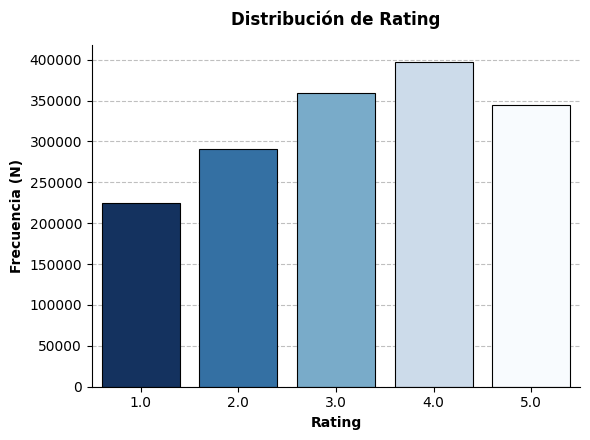

In [6]:
# @title
# Librerias utilizadas
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns
import missingno as msno

plt.figure(figsize=(6, 4.5))

# Gráfico de conteo
ax = sns.countplot(
    data=df,
    x='rating',
    hue='rating',
    palette='Blues_r',
    legend=False,
    edgecolor='black',
    linewidth=0.8,
)

# Estética
plt.title(
    'Distribución de Rating',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Rating', fontweight='bold')
plt.ylabel('Frecuencia (N)', fontweight='bold')

sns.despine(top=True, right=True)
ax.set_axisbelow(True)
plt.grid(axis='y', linestyle='--', alpha=0.5, color='gray')
plt.tight_layout()
plt.show()

## 2. El problema como MDP

### 2.1 Vocabulario

| Término | Significado en este TP |
|---|---|
| Política π | regla que, dado lo observado, elige qué ítem mostrar |
| Episodio | una sesión de 20 recomendaciones a un usuario |
| Retorno | suma de los ratings obtenidos en el episodio |
| Política de registro (o de comportamiento) | la que generó los logs de train |
| RL offline | aprender una política sólo con logs, sin poder probar recomendaciones nuevas con usuarios |

La dificultad central del RL offline es que **no se puede preguntar "¿qué hubiera pasado si…?"**. Si un ítem casi no aparece en los logs, no hay forma de saber cómo lo valoraría un usuario. Todo método offline tiene que decidir qué hacer con lo que los datos no cubren.

### 2.2 La formulación

| Elemento | En este TP |
|---|---|
| Estado s_t | lo observado hasta t: grupo (si es visible), ítems mostrados y ratings revelados, y el paso t |
| Acción a_t | el ítem que se muestra, entre los que todavía no se mostraron |
| Recompensa r_t | el rating que el usuario le da a a_t |
| Transición | se agrega (a_t, r_t) al historial |
| Horizonte | 20 pasos; el último es terminal |
| Descuento γ | a elegir; el retorno evaluado es la suma sin descontar |

El estado no es "el usuario", porque el usuario no es observable. Es **lo que la política sabe del usuario** en ese momento. Al principio de una sesión con grupo oculto, el estado está vacío. Después de unos pasos, los ratings revelados empiezan a decir algo sobre él.

### 2.3 Episodios y retorno pendiente

El retorno pendiente desde t es la suma de lo que falta obtener:

```
R̂_t = r_t + r_{t+1} + … + r_{T−1}
```

Ejemplo con un episodio de 4 pasos:

| t | a_t | r_t | R̂_t |
|---:|---|---:|---:|
| 0 | ítem 17 | 4 | 4 + 2 + 5 + 3 = 14 |
| 1 | ítem 302 | 2 | 2 + 5 + 3 = 10 |
| 2 | ítem 45 | 5 | 5 + 3 = 8 |
| 3 | ítem 9 | 3 | 3 |

R̂ baja paso a paso exactamente en el rating recibido: R̂_{t+1} = R̂_t − r_t.

In [7]:
from protocolo.datos import make_episodes

ep = make_episodes(train, length=20)   # tramos de 20 pasos consecutivos de cada usuario
print(ep.items.shape, ep.ratings.shape, ep.groups.shape)   # (N, 20) (N, 20) (N,)
rtg = ep.returns_to_go()                                   # (N, 20); rtg[:, 0] = retorno del episodio

(73827, 20) (73827, 20) (73827,)


Un usuario con 112 ítems aporta 5 episodios de 20 y descarta los 12 sobrantes. R̂ se calcula **dentro de cada episodio**, no sobre toda la trayectoria del usuario. Así su escala, entre 20 y 100, coincide con la de una sesión evaluada. Si se calculara sobre 112 ítems, R̂_0 rondaría 360 y el modelo nunca vería en entrenamiento valores como los que se le piden al evaluar.

### 2.4 Descuento y horizonte

Con γ = 1, todos los ratings de la sesión pesan igual. Con γ < 1, los futuros pesan menos. El protocolo evalúa la suma sin descontar, pero un método basado en valores como IQL puede entrenarse con γ < 1 porque estabiliza el aprendizaje.

Un caso extremo es γ = 0: el valor de una acción es sólo su recompensa inmediata, y el problema se trata como un **bandit contextual**, donde cada recomendación se decide sin pensar en las siguientes.

**Para pensar.** Si los ratings de un usuario sólo dependen de su grupo y del ítem, ¿en qué sentido una recomendación afecta a las siguientes? ¿Qué gana una política al tener en cuenta la secuencia?

## 3. El protocolo de evaluación

### 3.1 Por qué simular sesiones

Para medir cómo rinde una política hay que dejarla elegir y ver qué pasa. Con usuarios reales no se puede. Pero los usuarios de test tienen rating para **todos** los ítems, así que se puede simular una sesión:

```
reset(grupo o None)
repetir 20 veces:
    la política ve lo observado hasta ahora  →  devuelve un puntaje por ítem
    el protocolo descarta los ítems ya mostrados y elige el de mayor puntaje
    el protocolo revela el rating de ese ítem  →  recompensa
```

Como el rating de cualquier ítem está disponible, la política puede elegir lo que quiera y siempre hay una respuesta. Y como sólo se revela lo que se muestra, la política no puede hacer trampa mirando ratings futuros.

### 3.2 La interfaz `Policy`

Toda política, sea línea base o modelo, implementa dos métodos:

In [8]:
class Policy:
    def reset(self, group: int | None, horizon: int) -> None:
        """Inicio de sesión. group es None cuando el grupo está oculto."""

    def scores(self, items_seen: np.ndarray, ratings_seen: np.ndarray) -> np.ndarray:
        """Un puntaje por ítem del catálogo (n_items,). Mayor es mejor."""

`scores` recibe copias de lo observado en la sesión: en el paso t, `items_seen` y `ratings_seen` tienen largo t. La política devuelve un puntaje para cada uno de los n_items ítems. No hace falta que excluya los ya mostrados, porque el protocolo los descarta. Para un modelo neuronal, los puntajes suelen ser las logits de salida.

Ejemplo mínimo de una política propia y su evaluación:

In [9]:
from pathlib import Path

import numpy as np
from protocolo.baselines import ItemMeanPolicy
from protocolo.evaluar import evaluate, evaluate_grid, baseline_factories, write_reports
from protocolo.metricas import summarize
from protocolo.simulador import SessionConfig


class NoisyItemMean:
    """item_mean con ruido: sirve sólo para probar la interfaz."""

    def __init__(self, train, n_items, noise=0.5, seed=0):
        self.base = ItemMeanPolicy(train, n_items, by_group=False)
        self.noise = noise
        self.rng = np.random.default_rng(seed)

    def reset(self, group, horizon):
        self.base.reset(group, horizon)

    def scores(self, items_seen, ratings_seen):
        s = self.base.scores(items_seen, ratings_seen)
        return s + self.noise * self.rng.standard_normal(s.shape)


cfg = SessionConfig(horizon=20, warmup=0, group_visible=True)
df = evaluate(NoisyItemMean(train, n_items), test, n_items, cfg, seeds=[0])
print(summarize(df)[["normalized", "hit_rate"]])

     normalized            hit_rate          
           ci95      mean      ci95      mean
_all                                         
0      0.006096  0.606246  0.007795  0.830031


`evaluate` devuelve una fila por sesión. `summarize` agrega por usuario y calcula media e intervalo de confianza.

Para comparar varias políticas en las tres condiciones del protocolo:

In [ ]:
factories = {**baseline_factories(train, n_items), "noisy": lambda: NoisyItemMean(train, n_items)}
results = evaluate_grid(factories, test, n_items, horizon=20, warmups=(0, 5),
                        group_visibility=(True, False), seeds=(0, 1, 2))
write_reports(results, Path("outputs/mi_comparacion"))   # sesiones.csv, resumen.csv, resumen_por_grupo.csv

`factories` contiene funciones que **crean** la política, no la política misma. Así cada condición empieza con una política nueva.

### 3.3 Métricas

**Retorno normalizado (métrica principal).** El retorno crudo depende del usuario: uno que valora todo con 4 o 5 da retornos altos con cualquier política. Para comparar entre usuarios, se ubica el retorno entre dos referencias del mismo usuario:

```
normalizado = (retorno − retorno esperado al azar) / (retorno del oráculo − retorno esperado al azar)
```

- **Retorno esperado al azar:** el promedio de los ratings del usuario multiplicado por 20.
- **Retorno del oráculo:** la suma de sus 20 mejores ratings, como si se conocieran de antemano.

Ejemplo: un usuario con retorno esperado al azar de 64 y oráculo de 100. Una política que obtiene 85 tiene un normalizado de (85 − 64) / (100 − 64) = 0,58: cerró el 58 % de la distancia entre el azar y lo óptimo. Puede ser negativo si la política es peor que el azar.

**Hit rate.** Fracción de las recomendaciones de la sesión con rating ≥ 4.

**NDCG@10 y precision@10.** Miran sólo el **primer paso**: cómo ordena la política los ítems antes de observar nada. Un ítem es relevante si su rating es ≥ 4.

- **precision@10:** la fracción de relevantes entre los 10 primeros.
- **NDCG@10:** premia que los relevantes estén arriba, porque cada posición k pesa 1 / log₂(k + 1).

Ejemplo con k = 3, si los tres primeros son relevante, no relevante, relevante, y el usuario tiene 2 relevantes en total:

- DCG = 1 + 0 + 1/2 = 1,5;
- el ideal pondría los 2 relevantes primero: 1 + 0,63 = 1,63;
- NDCG = 1,5 / 1,63 = 0,92.

Son métricas de ranking estático, complementarias. La que mide la sesión es el retorno.

### 3.4 Las tres condiciones

| Condición | Qué sabe la política al empezar | Qué mide |
|---|---|---|
| Grupo visible, warm-up 0 | el grupo del usuario | si personaliza por grupo |
| Grupo oculto, warm-up 0 | nada (cold-start estricto) | si se adapta usando sólo los ratings que va viendo |
| Warm-up 5 | 5 ítems elegidos al azar y sus ratings | si aprovecha un historial inicial |

El warm-up **no es cold-start**: la política ya tiene información sobre el usuario. Las métricas cuentan sólo los 15 pasos que decide la política.

### 3.5 Validación y test

- **Validación:** sirve para elegir hiperparámetros, el retorno pedido al DT y τ, β y γ de IQL. `evaluate(policy, val, ...)` funciona igual que con test, pero los usuarios de validación sólo tienen ratings para los ítems de su trayectoria de train. Por eso el catálogo de cada sesión se restringe a esos ítems.
- **Comparabilidad:** los números de validación no se comparan con los de test, porque el catálogo es distinto. Sí sirven para comparar configuraciones entre sí.
- **Test:** se usa **una sola vez**, al final. Si se elige algo mirando test, el resultado de test deja de ser una estimación honesta.

**Semillas e intervalos.** Cada sesión tiene azar: desempates y ítems del warm-up. `evaluate` corre cada usuario con varias semillas, y `summarize` primero promedia las semillas de cada usuario y después calcula el intervalo del 95 % entre usuarios. Así el tamaño de muestra es la cantidad de usuarios, no de sesiones.

### 3.6 Las líneas base

| Línea base | Qué hace | Para qué sirve |
|---|---|---|
| `random` | elige al azar | define el 0 de la métrica |
| `popularity` | ordena por cantidad de apariciones en train | ¿alcanza con mostrar lo que más se mostró? |
| `item_mean` | ordena por rating medio en train | el mejor ranking **igual para todos** |
| `group_mean` | rating medio en el grupo del usuario, si es visible | personalización por segmento |
| `group_posterior` | infiere el grupo con los ratings que va viendo | adaptación explícita durante la sesión |

`group_posterior` hace algo que un modelo secuencial podría aprender por su cuenta. Ejemplo con 2 grupos y ratings con desvío 1:

- el ítem 0 tiene media 4,5 en el grupo A y 1,5 en el grupo B;
- al principio, cada grupo tiene probabilidad 0,5;
- el usuario le da 5 al ítem 0, que está a 0,5 de la media de A y a 3,5 de la de B;
- por la regla de Bayes, la probabilidad de A pasa a 0,998.

Desde ese momento recomienda como si el usuario fuera de A. Con 8 grupos y ratings ruidosos hacen falta algunas observaciones más, pero la idea es la misma.

Una línea base no es un rival a vencer a toda costa. Ubica los resultados: si un modelo no supera a `item_mean`, no está personalizando, aunque su pérdida baje.

## 4. Decision Transformer

### 4.1 La idea

El DT (Chen et al., 2021) convierte el RL offline en **aprendizaje supervisado sobre trayectorias**. En vez de estimar valores, aprende directamente:

```
P(a_t | R̂_t, s_t, historia previa)
```

O sea, "qué acción aparecía en los datos cuando faltaba obtener R̂_t y la situación era s_t".

- **Al entrenar:** cada trayectoria de los logs se convierte en ejemplos de clasificación. El target es el ítem registrado y la entrada incluye el retorno que **efectivamente** se obtuvo desde ahí.
- **Al recomendar:** se le pide un retorno alto. Si en los datos había trayectorias con ese retorno, el modelo tiende a elegir acciones como las de ellas.

No hay función de valor, ni bootstrapping, ni máximo sobre acciones. El DT **imita lo que hay en los datos, condicionado por el retorno**. Por eso lo que puede aprender depende de qué trayectorias contienen esos datos y de qué tienen de distinto las de retorno alto respecto de las de retorno bajo.

### 4.2 Tokens y alineación

El DT ve un episodio como una secuencia de tokens. Por cada paso t hay tres:

```
R̂_0  s_0  a_0  R̂_1  s_1  a_1  …  R̂_19  s_19  a_19
```

Con el episodio del ejemplo de la sección 2.3, y el rating anterior como estado:

| Posición | Token | Valor |
|---:|---|---|
| 0 | R̂_0 | 14 |
| 1 | s_0 | grupo 3, "sin rating previo" |
| 2 | a_0 | ítem 17 |
| 3 | R̂_1 | 10 |
| 4 | s_1 | grupo 3, rating previo 4 |
| 5 | a_1 | ítem 302 |
| … | … | … |

**La máscara causal** hace que cada token sólo vea los anteriores. Para dos pasos, con 6 tokens, ✓ significa "puede ver":

```
          R̂_0 s_0 a_0 R̂_1 s_1 a_1
R̂_0        ✓
s_0        ✓   ✓
a_0        ✓   ✓   ✓
R̂_1        ✓   ✓   ✓   ✓
s_1        ✓   ✓   ✓   ✓   ✓
a_1        ✓   ✓   ✓   ✓   ✓   ✓
```

**a_t se predice desde la salida del token s_t.** Esa salida ya vio R̂_≤t, s_≤t y a_<t, pero no a_t. Si se predijera desde la salida del token a_t, el modelo vería la respuesta y la pérdida bajaría a casi cero sin aprender nada útil. Con esa fuga, el TP no es válido.

**Qué va en s_t** es una decisión de diseño a justificar. Por ejemplo, el grupo (o un token "desconocido") más el rating del paso anterior. Recordar que s_t no puede incluir r_t: ese rating se revela recién después de mostrar a_t.

**Cómo se representa cada token:**

- **R̂:** es un número. Se escala, por ejemplo dividiendo por 100, y se proyecta con una capa lineal.
- **Ítems:** se representan con una tabla de embeddings.
- **Paso t:** se suma un embedding de t, el mismo para los tres tokens del paso.
- **Tipo de token:** se suma otro embedding que distingue R̂, s y a.

La capa de salida produce una logit por ítem. Una opción habitual es compartir sus pesos con la tabla de embeddings de ítems.

| Tensor | Forma | Contenido |
|---|---|---|
| `rtg` | (B, T) | R̂_t de cada paso |
| `items` | (B, T) | a_t, ítems registrados |
| estado | (B, T) o (B,) | lo que se decida poner en s_t |
| salida | (B, T, n_items) | logits de a_t, desde el token s_t |

**Ítems ya mostrados.** En los datos no hay repeticiones dentro de un episodio, y el protocolo tampoco las permite. Entonces, en el paso t, los ítems de a_0 … a_{t−1} nunca pueden ser el target. Hay que enmascarar sus logits con −∞, tanto al entrenar como al recomendar. Así el modelo no gasta capacidad en aprender que no se repite.

### 4.3 Esqueleto

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DecisionTransformer(nn.Module):
    def __init__(self, n_items: int, horizon: int = 20, d_model: int = 128, n_layers: int = 3, n_heads: int = 4):
        super().__init__()
        # TODO: embeddings para R̂, estado, ítem, paso t y tipo de token (R̂ / s / a)
        # TODO: bloques transformer (nn.TransformerEncoder con norm_first=True funciona bien)
        # TODO: proyección de salida a n_items (puede compartir pesos con el embedding de ítems)
        raise NotImplementedError

    def forward(self, rtg, items, state, groups) -> torch.Tensor:
        """Devuelve logits (B, T, n_items) para a_t, calculados desde el token s_t."""
        # TODO: construir los tokens R̂_t, s_t, a_t de forma (B, T, d)
        # TODO: intercalarlos en (B, 3T, d): R̂_0, s_0, a_0, R̂_1, ...
        # TODO: máscara causal (3T, 3T)
        # TODO: pasar por el transformer y quedarse con las salidas de los tokens s_t (posiciones 1, 4, 7, ...)
        raise NotImplementedError


def seen_before_mask(items: torch.Tensor, n_items: int) -> torch.Tensor:
    """(B, T, n_items): True si el ítem ya se mostró antes del paso t en el episodio."""
    # TODO: one-hot de items, suma acumulada en T, desplazar un paso
    raise NotImplementedError


def dt_loss(model, batch) -> torch.Tensor:
    logits = model(batch["rtg"], batch["items"], batch["state"], batch["groups"])
    logits = logits.masked_fill(seen_before_mask(batch["items"], logits.shape[-1]), float("-inf"))
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), batch["items"].reshape(-1))

`seen_before_mask` en un ejemplo con items = [17, 302, 45]:

- en t = 0 no enmascara nada;
- en t = 1 enmascara el 17;
- en t = 2 enmascara el 17 y el 302.

### 4.4 Entrenamiento

- **Datos:** los episodios de `make_episodes(train, 20)`. Cada episodio aporta 20 ejemplos de clasificación, uno por paso, que se calculan juntos en una sola pasada gracias a la máscara causal.
- **Optimizador:** AdamW con un scheduler, por ejemplo OneCycle, y recorte de gradiente.
- **Validación:** monitorear la cross-entropy en `make_episodes(val, 20)` y guardar el checkpoint con la menor.
- **Cómo leer la pérdida:** compararla con la de una predicción uniforme sobre el catálogo, log(n_items), que es log(752) ≈ 6,62 en Netflix. La pérdida mide qué tan bien el modelo **imita** los logs, no qué tan bien recomienda. Si los logs son poco predecibles, la pérdida baja poco aunque el modelo aprenda algo útil, y al revés. La calidad se mide con el protocolo.
- **Grupo oculto:** si el modelo siempre ve el grupo al entrenar, no sabe qué hacer con el token "desconocido" al evaluar con grupo oculto. Una solución es reemplazar el grupo por "desconocido" en una fracción de los episodios de train, por ejemplo el 30 %. Si se hace, declararlo.

**Test obligatorio de no fuga.** Cambiar a_t y todo lo que viene después no debe cambiar las logits del paso t:

In [ ]:
def test_prediction_at_t_ignores_current_and_future_tokens(model, batch, t=7):
    model.eval()
    base = model(batch["rtg"], batch["items"], batch["state"], batch["groups"])[:, t]
    n_items = base.shape[-1]
    items2 = batch["items"].clone()
    items2[:, t:] = torch.randint(0, n_items, items2[:, t:].shape)
    rtg2 = batch["rtg"].clone()
    rtg2[:, t + 1:] = 0.0
    # TODO: alterar también el estado de los pasos > t
    out = model(rtg2, items2, batch["state"], batch["groups"])[:, t]
    assert torch.allclose(base, out, atol=1e-5)

Si este test falla, hay una fuga en la máscara o en la alineación, y ningún resultado posterior es válido.

### 4.5 Del modelo a una política

Al recomendar, el modelo se usa de forma autorregresiva. Se fija un retorno objetivo, por ejemplo 90, y en cada paso:

1. R̂_t = objetivo − suma de los ratings ya revelados.
2. Se arma la secuencia R̂_0, s_0, a_0, …, R̂_t, s_t con lo observado. En la posición de a_t, que todavía no existe, se pone un relleno cualquiera: la salida de s_t no lo ve.
3. Las logits del paso t son los puntajes.

Ejemplo con objetivo 90: si los dos primeros ratings fueron 5 y 4, en el paso 2 se pide R̂_2 = 90 − 9 = 81 para los 18 pasos restantes.

In [ ]:
class DTPolicy:
    def __init__(self, model, target_return: float):
        self.model = model.eval()
        self.target = target_return

    def reset(self, group, horizon):
        self.group = group          # None = oculto: usar el token "desconocido"

    @torch.no_grad()
    def scores(self, items_seen, ratings_seen):
        t = len(items_seen)
        # TODO: R̂ de cada paso: objetivo menos la suma de los ratings ya revelados
        # TODO: secuencia de longitud t + 1; el a_t de la posición t es un relleno que s_t no ve
        # TODO: estado de cada paso con lo observado
        # TODO: devolver las logits del paso t como numpy (n_items,)
        raise NotImplementedError

Con warm-up, los ítems del warm-up llegan en `items_seen` y sus ratings también se restan de R̂. El objetivo se refiere a los 20 pasos de la sesión completa.

### 4.6 Return conditioning

El retorno pedido es una **condición de entrada**, no una garantía. El experimento consiste en variar el retorno pedido y medir el obtenido:

1. Calcular la distribución de retornos de los episodios de train. Elegir retornos pedidos dentro de su soporte, por ejemplo los percentiles 10, 25, 50, 75, 90 y 99, y agregar uno o dos por encima del máximo.
2. Elegir en `val` el retorno pedido que da mejor normalizado. Ese es el que se usa en la tabla final.
3. En test, graficar el retorno obtenido frente al pedido, con la diagonal y el máximo de train marcados. Hacerlo para el agregado y para cada grupo.

Cómo leer el gráfico:

- **Sobre la diagonal:** el modelo obtiene lo que se le pide.
- **Por debajo, plano:** el modelo no distingue entre pedir un poco más o un poco menos.
- **Más allá del máximo de train:** el modelo nunca vio esos valores. Lo que haga ahí es extrapolación.

**Para pensar.** ¿Hasta dónde el retorno obtenido sigue al pedido? ¿Qué pasa fuera del soporte? ¿Los grupos se comportan igual? ¿El mejor retorno pedido es el más alto?

## 5. IQL

### 5.1 Valores y el problema del máximo

IQL pertenece a otra familia de métodos: los que estiman **cuánto vale** cada situación y cada acción.

- **Q(s, a):** el retorno esperado si en el estado s se muestra el ítem a y después se sigue la política.
- **V(s):** el retorno esperado desde s.
- **A(s, a) = Q(s, a) − V(s):** la **ventaja**, o sea, cuánto mejor que lo esperado es mostrar a. Si es positiva, a es mejor que lo habitual en s.

Q-learning aprende Q con la ecuación de Bellman:

```
Q(s, a) ← r + γ · max_a' Q(s', a')
```

En RL online esto funciona porque, si Q sobreestima una acción, el agente la prueba, ve que era mala y corrige. **En RL offline no puede probarla.** Ese máximo recorre los 752 ítems, incluidos los que casi no aparecen en los logs, y su Q está mal estimada. Si algún error es optimista, el máximo lo elige. El bootstrapping propaga ese error hacia atrás, de un paso a otro. Es el **error de extrapolación**, el problema central del RL offline basado en valores.

### 5.2 La solución de IQL

IQL (Kostrikov et al., 2022) **nunca evalúa Q en acciones que no están en los datos**. Reemplaza el máximo por algo que sólo usa las acciones registradas.

**V por regresión de expectil.** La regresión con error cuadrático aprende la media. La de expectil usa un error cuadrático **asimétrico**:

```
L_τ(u) = |τ − 1(u < 0)| · u²
```

Con τ > 0,5, quedarse por debajo de un valor cuesta más que pasarse. El resultado se corre hacia los valores altos. Ejemplo: si en un estado los datos tienen cuatro acciones con Q = 1, 2, 3 y 10:

| τ | Expectil |
|---:|---:|
| 0,5 | 4,0 (la media) |
| 0,7 | 5,5 |
| 0,9 | 8,0 |
| 0,99 | 9,8 |

Al acercar τ a 1, el expectil se acerca al máximo (10), pero **sólo entre las acciones que aparecen en los datos**. Así V(s) aproxima "el mejor valor que se ve en los datos desde s" sin preguntar por ítems no observados.

En este TP el estado es un historial y casi nunca se repite exactamente. La red no ve "cuatro acciones en el mismo estado", sino muchos estados parecidos con acciones distintas. La regresión de expectil funciona igual, porque la red generaliza entre estados similares.

**Q por diferencias temporales, usando V.** El objetivo de Q usa V(s') en vez del máximo:

```
Q(s_t, a_t) ← r_t + γ · V(s_{t+1})      (en el último paso: sólo r_t)
```

**π por regresión ponderada por ventaja (AWR).** Q y V no son una política: hay que extraerla. AWR entrena π como una clasificación de la acción registrada, igual que behavior cloning, pero con un peso por ejemplo:

```
peso = exp(β · (Q(s, a) − V(s)))
```

Ejemplo con cuatro acciones registradas de ventajas −1, 0, 0,5 y 1. Cada valor es la fracción del peso total que recibe esa acción:

| β | A = −1 | A = 0 | A = 0,5 | A = 1 |
|---:|---:|---:|---:|---:|
| 1 | 6 % | 17 % | 29 % | 47 % |
| 3 | 0 % | 4 % | 18 % | 78 % |
| 10 | 0 % | 0 % | 1 % | 99 % |

- **β cerca de 0:** todos los pesos son iguales y AWR se reduce a behavior cloning.
- **β grande:** casi todo el peso va a la mejor acción **de los datos**.

Como π sólo se entrena con acciones registradas, se queda dentro del soporte, y esa es la diferencia clave con tomar el máximo de Q. Los pesos se truncan, por ejemplo en 100, para que unos pocos ejemplos no dominen el gradiente.

### 5.3 Pérdidas

Con a la acción registrada en s, Q̄ la red objetivo y u = Q̄(s, a) − V(s):

```
L_V = E[ |τ − 1(u < 0)| · u² ]
L_Q = E[ (r + γ · (1 − terminal) · V(s') − Q(s, a))² ]
L_π = E[ min(exp(β · (Q̄(s, a) − V(s))), w_max) · (−log π(a | s)) ]
```

**Red objetivo.** Q̄ es una copia de Q que se actualiza lentamente con un promedio de Polyak: Q̄ ← (1 − λ) Q̄ + λ Q, con λ ≈ 0,005 en cada paso. Sin ella, V se entrenaría contra una Q que cambia en cada paso, y Q contra una V que a su vez depende de Q. Esa persecución mutua suele volverse inestable.

**Los gradientes no se mezclan:**

- L_V sólo actualiza V;
- L_Q sólo actualiza Q, por eso V(s') entra sin gradiente;
- L_π sólo actualiza π, por eso los pesos se calculan sin gradiente.

### 5.4 Representación del estado

El estado es el historial de la sesión. Una opción es un codificador que recorre los pares (ítem, rating) previos, como una GRU o un transformer causal, y les suma el grupo (o "desconocido") y el paso t.

El codificador tiene que devolver **T + 1 estados**, porque el objetivo del paso t usa V(s_{t+1}):

```
h_0 = codificar(grupo, historial vacío)               → estado antes de recomendar a_0
h_1 = codificar(grupo, (a_0, r_0))                    → estado antes de a_1
…
h_T = codificar(grupo, (a_0, r_0) … (a_{T−1}, r_{T−1})) → estado final (sólo para V)
```

En el paso t:

- Q(s_t, a_t) se lee de la salida de h_t en la posición del ítem a_t;
- V(s_{t+1}) se lee de h_{t+1}.

Decisiones a documentar:

- ¿Q, V y π comparten el codificador o cada uno tiene el suyo? Si lo comparten, ¿qué pérdida entrena el codificador?
- ¿La recompensa se usa cruda o centrada? Centrar, por ejemplo (r − 3) / 2, no cambia qué acción es mejor, pero cambia la escala de Q, V y las ventajas, y por lo tanto el efecto de β.
- Para π y para el máximo de Q, los ítems ya mostrados se enmascaran, igual que en el DT.

### 5.5 Esqueleto

In [ ]:
def expectile_loss(diff: torch.Tensor, tau: float) -> torch.Tensor:
    """diff = Q_obj - V. Penaliza más los casos con diff > 0 cuando tau > 0,5."""
    # TODO
    raise NotImplementedError


def iql_losses(model, batch, gamma: float, tau: float, beta: float, max_weight: float = 100.0):
    items, ratings, groups = batch["items"], batch["ratings"], batch["groups"]   # (B, T), (B, T), (B,)
    T = items.shape[1]
    r = ...           # TODO: recompensa, cruda o centrada
    not_done = ...    # TODO: 1 en los pasos 0..T-2, 0 en el último

    with torch.no_grad():
        q_obj = ...   # TODO: Q objetivo en la acción registrada, (B, T)

    v_all = ...       # TODO: V de los T + 1 estados, (B, T + 1)
    loss_v = expectile_loss(q_obj - v_all[:, :T], tau)

    q = ...           # TODO: Q en la acción registrada, (B, T)
    td_target = ...   # TODO: r + gamma * not_done * V(s'), sin gradiente a través de V
    loss_q = F.mse_loss(q, td_target)

    weights = ...     # TODO: exp(beta * (q_obj - V)), sin gradiente, truncado en max_weight
    logits = ...      # TODO: logits de π, con los ítems ya mostrados enmascarados
    loss_pi = ...     # TODO: cross-entropy ponderada por weights

    return {"v": loss_v, "q": loss_q, "pi": loss_pi}

`torch.gather` sirve para quedarse con Q en la acción registrada: `q_all.gather(-1, items.unsqueeze(-1)).squeeze(-1)` toma, de una salida (B, T, n_items), el valor del ítem registrado en cada paso.

### 5.6 Entrenamiento

- **Optimizadores:** uno para cada red (Q, V y π). Se pueden sumar las tres pérdidas y hacer un solo `backward`, siempre que cada pérdida sólo llegue a su red.
- **Red objetivo:** actualizar Q̄ después de cada paso de optimización.
- **Episodios:** los mismos que usa el DT.
- **Qué mirar en las curvas:** las pérdidas y también el peso medio de AWR.
  - Si casi todos los pesos están truncados, β es demasiado grande para la escala de las ventajas.
  - Si todos valen alrededor de 1, π es casi behavior cloning.
- **Las pérdidas no miden la calidad.** Las de Q y π pueden **subir** mientras la política mejora. V va incorporando valor futuro, los objetivos de Q cambian y los pesos de π se vuelven más selectivos. Se elige con el protocolo en validación.

### 5.7 Dos políticas a partir del mismo modelo

Un modelo IQL entrenado permite recomendar de dos formas:

- **`pi`:** ordenar por las logits de π, que es lo que propone IQL.
- **`q`:** ordenar por Q(s, a) sobre todos los ítems disponibles. Es el máximo de Q que IQL evita al entrenar, aplicado al recomendar.

In [ ]:
class IQLPolicy:
    def __init__(self, model, mode: str = "pi"):   # "pi": AWR; "q": máximo de Q
        ...

    def reset(self, group, horizon):
        ...

    @torch.no_grad()
    def scores(self, items_seen, ratings_seen):
        # TODO: codificar el historial y devolver las logits de π o los valores de Q del estado actual
        raise NotImplementedError

Evaluar las dos en las tres condiciones. La consigna pide explicar en qué se diferencian, relacionándolo con la sección 5.1.

### 5.8 Experimentos

- **Barrido en validación:** τ ∈ {0,7; 0,9}, β ∈ {3; 10} y γ, elegidos con el protocolo, no con las pérdidas.
- **γ = 0 frente a γ > 0,** por ejemplo 0,9. Con γ = 0, Q sólo predice la recompensa inmediata y el problema se trata como un bandit contextual. Si γ > 0 no mejora, preguntarse qué valor futuro había para aprender (sección 2.4).
- **`pi` frente a `q`** en las tres condiciones.

## 6. Calidad de los logs

### 6.1 La idea

Los logs originales vienen de una política uniforme. En un sistema real no es así: los logs los produce el recomendador que estaba en producción, que muestra más lo que cree bueno. `protocolo/logs.py` simula ese caso con los mismos ratings, sin inventar ninguno.

El "sistema anterior":

- conoce el grupo del usuario;
- en cada paso, con probabilidad ε, elige un ítem al azar (explora);
- si no, elige con probabilidad proporcional a exp(media del ítem en el grupo / τ).

La temperatura τ controla qué tan concentrado está. Con τ chico casi siempre elige los mejores; con τ grande se parece al azar. Esta τ no tiene relación con el expectil de IQL.

Para cada usuario de train, el sistema anterior corre sesiones de 20 pasos en el simulador, eligiendo entre los ítems que ese usuario valoró. Así cada rating registrado es real. Para no hacer trampa, las medias que usa con cada usuario excluyen las valoraciones de ese mismo usuario.

| Preset | Qué contiene |
|---|---|
| `random` | los logs originales |
| `mixto` | cada sesión toma ε al azar entre 0; 0,25; 0,5 y 1: sesiones buenas, regulares y aleatorias mezcladas |
| `experto` | casi todas las sesiones son del sistema anterior explotando (ε = 0,1, τ chico) |

### 6.2 Uso

In [ ]:
from protocolo.logs import logged_episodes, logs_cache

logs = "mixto"   # o "experto", o "random" para los originales
train_eps = logged_episodes(logs, train, train, n_items, 20, seed=0, cache=logs_cache(dataset, logs, "train"))
val_eps = logged_episodes(logs, val, train, n_items, 20, seed=1, cache=logs_cache(dataset, logs, "val"))

ep = train_eps.episodes          # mismo formato que make_episodes
print(ep.ratings.sum(1).mean())  # retorno medio de un episodio de train
baseline_train = train_eps.logged_users()   # para ajustar las líneas base con estos logs

La primera vez tarda menos de un minuto y guarda el resultado en `outputs/logs/`. Las siguientes lo leen de ahí.

Las líneas base ajustadas con esos logs, más el sistema anterior como referencia:

In [ ]:
%%bash
python -m protocolo.evaluar --dataset netflix --logs mixto --output outputs/baselines_netflix_mixto

**Las líneas base se ajustan con los mismos logs que los modelos.** Un equipo real sólo tiene los logs de su sistema. Si las líneas base usaran los logs aleatorios y el modelo los del sistema anterior, la comparación mezclaría dos fuentes de información distintas.

### 6.3 Actividad

Entrenar el DT e IQL con los logs `random` y con los `mixto`, sin cambiar nada más, y comparar con las líneas base ajustadas con los mismos logs.

Un concepto útil para interpretar los resultados es el **sesgo de selección**. Cuando una política decide qué se muestra, qué se observa deja de ser una muestra al azar. Un promedio calculado sobre lo observado puede no representar lo que pasaría con cualquier usuario.

**Para pensar.**

- ¿Algún modelo supera al sistema anterior que generó sus datos? ¿Por qué podría hacerlo?
- ¿Por qué cambia tanto `popularity` entre un dataset y otro?
- ¿Qué le pasa a `item_mean` cuando los ítems no se muestran al azar? ¿Y a `group_mean`?

## 7. Semillas y reporte

Un modelo entrenado con otra semilla (otra inicialización, otro orden de los datos) da otro resultado. Hay dos fuentes de variabilidad y conviene separarlas:

- **Dispersión entre semillas de entrenamiento:** cuánto cambia el resultado al reentrenar. Se estima entrenando al menos 3 veces.
- **IC 95 % por usuario** (`summarize`): cuánto cambiaría al evaluar con otros usuarios del mismo tipo.

Una mejora menor que la dispersión entre semillas no es una mejora: con otra semilla podría desaparecer. Tampoco vale reportar la mejor de varias semillas.

In [ ]:
import pandas as pd

rows = []
for seed in (0, 1, 2):
    df = pd.read_csv(f"outputs/dt_seed{seed}/eval/test/sesiones.csv")   # ajustar a la ruta de cada grupo
    per_cond = df.groupby(["policy", "warmup", "group_visible"])["normalized"].mean()
    rows.append(per_cond.rename(seed))
by_seed = pd.concat(rows, axis=1)
summary = pd.DataFrame({"media": by_seed.mean(1), "desvío entre semillas": by_seed.std(1)})

Tabla mínima del reporte, para cada tipo de logs:

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | | | | |
| `popularity` | | | | |
| `item_mean` | | | | |
| `group_mean` | | | | |
| `group_posterior` | | | | |
| DT (R̂ elegido en val.) | | | | |
| IQL π | | | | |
| IQL, máximo de Q | | | | |

Un buen reporte no sólo muestra la tabla: explica **por qué** cada modelo queda donde queda, usando lo aprendido en la exploración (sección 1.4) y en los experimentos.

## 8. Errores frecuentes

- Evaluar con "el siguiente ID" del JSON de test.
- Predecir a_t desde el token a_t, o dejar que el estado del paso t incluya r_t.
- Calcular R̂ sobre toda la trayectoria del usuario en vez de dentro del episodio de 20 pasos.
- Elegir el retorno pedido, τ, β o γ mirando test.
- Ajustar las líneas base con usuarios de validación o test.
- Separar train y validación por interacciones en lugar de por usuarios.
- Bootstrapear en el último paso del episodio en IQL.
- Calcular los pesos de AWR con gradiente a través de Q o V.
- Concluir algo por una pérdida que baja, sin evaluar con el protocolo.
- Comparar números de validación con números de test, o de protocolos distintos.
- Reportar una sola semilla o la mejor de varias.

## 9. Preguntas para discutir

1. Si la política de registro es uniforme, ¿qué información contienen las trayectorias de retorno alto?
2. ¿Qué diferencia hay entre "imitar las sesiones que salieron bien" (DT) y "elegir acciones mejores que el promedio en cada estado" (IQL)?
3. ¿Por qué IQL no necesita evaluar Q en ítems que no aparecen en los datos? ¿Qué pasa si igual se elige el máximo de Q?
4. ¿Qué tendría que pasar en el generador para que el orden de las recomendaciones importe más? Por ejemplo, saturación por género o abandono tras ratings bajos.
5. ¿Qué haría falta para que un modelo aprenda lo que hace `group_posterior`?

## 10. Referencias

- Chen et al. (2021). *Decision Transformer: Reinforcement Learning via Sequence Modeling.* NeurIPS.
- Kostrikov, Nair y Levine (2022). *Offline Reinforcement Learning with Implicit Q-Learning.* ICLR.
- Peng et al. (2019). *Advantage-Weighted Regression: Simple and Scalable Off-Policy Reinforcement Learning.*
- Levine et al. (2020). *Offline Reinforcement Learning: Tutorial, Review, and Perspectives on Open Problems.*
- Li et al. (2011). *Unbiased Offline Evaluation of Contextual-Bandit-based News Article Recommendation Algorithms.* WSDM.
- Fu et al. (2020). *D4RL: Datasets for Deep Data-Driven Reinforcement Learning.*